# Assignment 2 – K-Nearest Neighbors ~~& Timeseries Forecasting~~ 
## Part 1 – KNN

## Import Libraries

In [199]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Load and check Dataset

In [200]:
df = pd.read_csv('airline_passenger_satisfaction.csv')
display(df.head().T)

,0,1,2,3,4
ID,1,2,3,4,5
Gender,Male,Female,Male,Male,Female
Age,48,35,41,50,49
Customer Type,First-time,Returning,Returning,Returning,Returning
Type of Travel,Business,Business,Business,Business,Business
Class,Business,Business,Business,Business,Business
Flight Distance,821,821,853,1905,3470
Departure Delay,2,26,0,0,0
Arrival Delay,5.0,39.0,0.0,0.0,1.0
Departure and Arrival Time Convenience,3,2,4,2,3


# Describe Variables


In [201]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
ID,129880.0,64940.50,37493.27,1.0,32470.75,64940.5,97410.25,129880.0
Age,129880.0,39.43,15.12,7.0,27.00,40.0,51.00,85.0
Flight Distance,129880.0,1190.32,997.45,31.0,414.00,844.0,1744.00,4983.0
Departure Delay,129880.0,14.71,38.07,0.0,0.00,0.0,12.00,1592.0
Arrival Delay,129487.0,15.09,38.47,0.0,0.00,0.0,13.00,1584.0
Departure and Arrival Time Convenience,129880.0,3.06,1.53,0.0,2.00,3.0,4.00,5.0
Ease of Online Booking,129880.0,2.76,1.40,0.0,2.00,3.0,4.00,5.0
Check-in Service,129880.0,3.31,1.27,0.0,3.00,3.0,4.00,5.0
Online Boarding,129880.0,3.25,1.35,0.0,2.00,3.0,4.00,5.0
Gate Location,129880.0,2.98,1.28,0.0,2.00,3.0,4.00,5.0


# Plot Variables

In [202]:
numerical = [
    'Age',
    'Flight Distance',
    'Departure Delay',
    'Arrival Delay'
]

non_numerical = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class',
    'Satisfaction',
    'Departure and Arrival Time Convenience',
    'Ease of Online Booking',
    'Check-in Service',
    'Online Boarding',
    'Gate Location',
    'On-board Service',
    'Seat Comfort',
    'Leg Room Service',
    'Cleanliness',
    'Food and Drink',
    'In-flight Service',
    'In-flight Wifi Service',
    'In-flight Entertainment',
    'Baggage Handling'
]

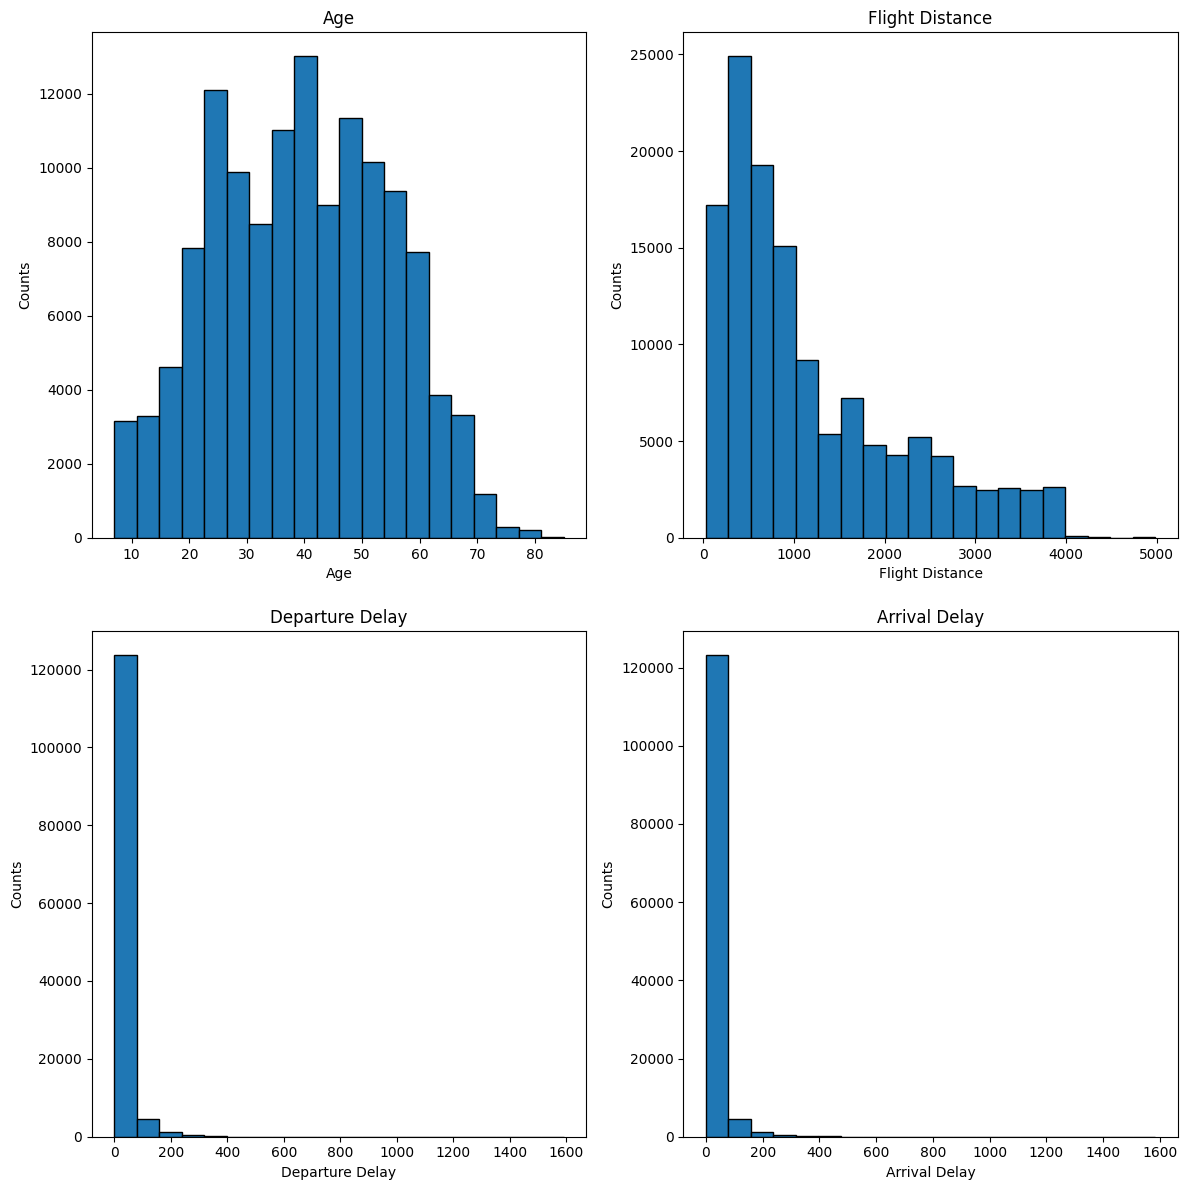

In [203]:
hvars = df[numerical]
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

for i, col in enumerate(hvars):
  axes[i].hist(hvars[col], bins=20, edgecolor='black')
  axes[i].set_title(col)
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Counts')

plt.tight_layout(h_pad=2)
plt.show()

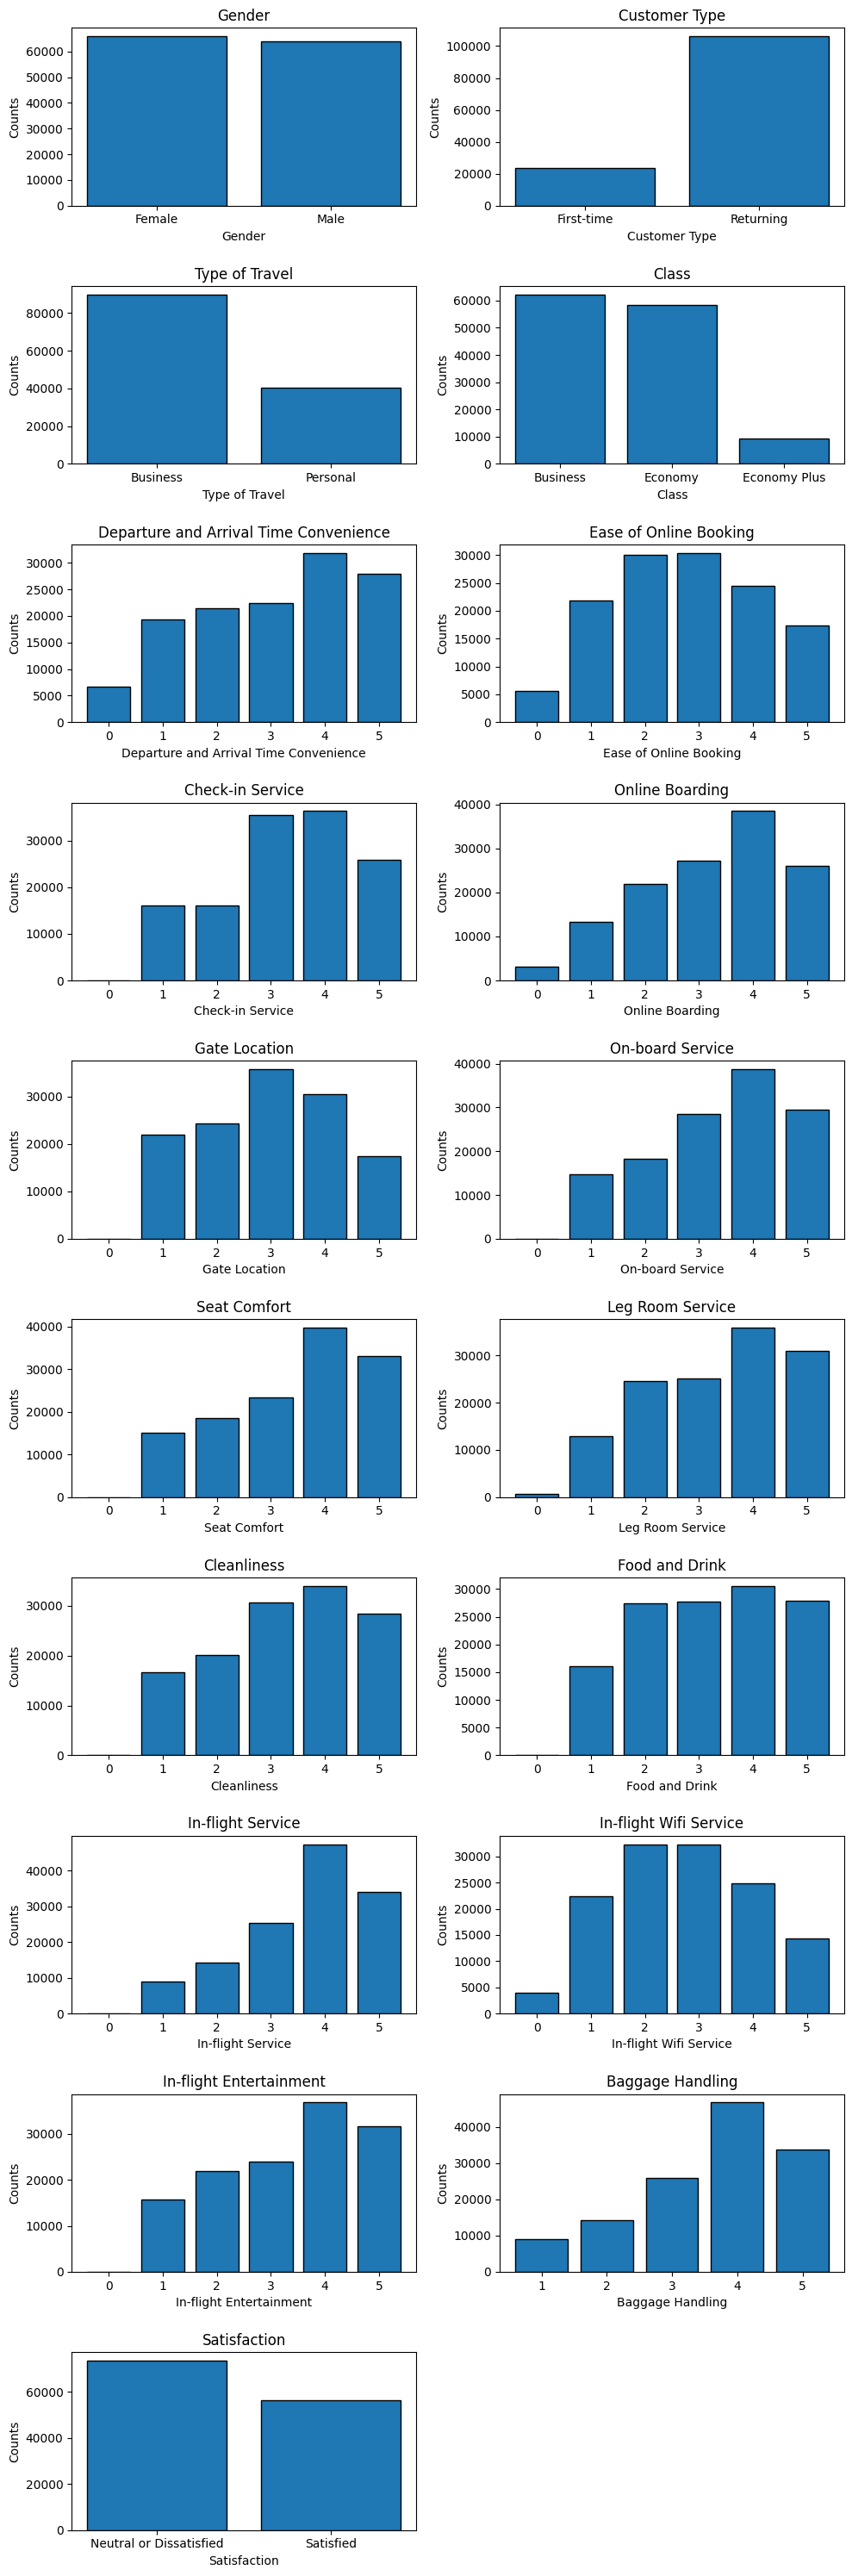

In [204]:
bvars = df.drop(columns=['ID'] + numerical)
fig, axes = plt.subplots(10, 2, figsize=(10, 30))
axes = axes.flatten()

for i, col in enumerate(bvars.columns):
  counts = bvars[col].value_counts().sort_index()

  axes[i].bar(
      counts.index.astype(str),
      counts.values,
      edgecolor='black'
  )
  axes[i].set_title(col)
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Counts')
axes[len(non_numerical)].set_visible(False)

plt.tight_layout(h_pad=2)
plt.show()


In [205]:
counts = df['Satisfaction'].value_counts()

satisfaction = pd.DataFrame({
    'Count': counts,
    'Percentage': (counts / counts.sum() * 100).round(2)
})

display(satisfaction)

,Count,Percentage
Satisfaction,,
Neutral or Dissatisfied,73452,56.55
Satisfied,56428,43.45


The "Neutral or Dissatisfied" class outweighs the "Satisfied" class, accounting for 56.55% of the data. 56.55% of the passengers are *not* "Satisfied".

# 2. Encode data

In [206]:
print(f'Shape: {df.shape[0],df.shape[1]}')
print(f'Missing Values: { df.isna().sum().sum() }\n')

for col in non_numerical:
  print(df[col].unique())

var_encoding = {
    'Gender': {'Female': 0, 'Male': 1},
    'Customer Type': {'First-time': 0, 'Returning': 1},
    'Type of Travel': {'Business': 0, 'Personal': 1},
    'Class': {'Business': 0, 'Economy': 1, 'Economy Plus': 2},
    'Satisfaction': {'Neutral or Dissatisfied': 0, 'Satisfied': 1}
}

df_encoded = df.replace(var_encoding)

og_rows = len(df_encoded)
df_encoded = df_encoded.dropna(subset=numerical).reset_index(drop=True)
display(pd.DataFrame(df_encoded))

print(f'Dataset: {og_rows}')
print(f'Removed: {og_rows}')
print(f'Result: { len(df_encoded)}')

display(df_encoded.head())

Shape: (129880, 24)
Missing Values: 393

['Male' 'Female']
['First-time' 'Returning']
['Business' 'Personal']
['Business' 'Economy' 'Economy Plus']
['Neutral or Dissatisfied' 'Satisfied']
[3 2 4 1 5 0]
[3 2 4 1 5 0]
[4 3 1 2 5 0]
[3 5 4 2 1 0]
[3 2 4 1 5 0]
[3 5 4 2 1 0]
[5 4 3 2 1 0]
[2 5 3 4 1 0]
[5 4 3 2 1 0]
[5 3 4 2 1 0]
[5 3 4 1 2 0]
[3 2 4 1 0 5]
[5 3 4 2 1 0]
[5 3 4 1 2]


C:\Users\apkec\AppData\Local\Temp\ipykernel_32916\2624309493.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_encoded = df.replace(var_encoding)


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,1,48,0,0,0,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,0
1,2,0,35,1,0,0,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,1
2,3,1,41,1,0,0,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,1
3,4,1,50,1,0,0,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,1
4,5,0,49,1,0,0,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129482,129876,1,28,1,1,2,447,2,3.0,4,...,5,1,4,4,4,5,4,4,4,0
129483,129877,1,41,1,1,2,308,0,0.0,5,...,5,2,5,2,2,4,3,2,5,0
129484,129878,1,42,1,1,2,337,6,14.0,5,...,3,3,4,3,3,4,2,3,5,0
129485,129879,1,50,1,1,2,337,31,22.0,4,...,4,4,5,3,3,4,5,3,5,1


Dataset: 129880
Removed: 129880
Result: 129487


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,1,48,0,0,0,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,0
1,2,0,35,1,0,0,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,1
2,3,1,41,1,0,0,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,1
3,4,1,50,1,0,0,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,1
4,5,0,49,1,0,0,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,1


Some rows do not contain numerical values as expected so they are removed from the dataset.

# 3. Convert DataFrame to Numpy arrays

In [207]:
input_df = df_encoded.drop(columns=['ID', 'Satisfaction'])
targets_df = df_encoded['Satisfaction']

x = input_df.to_numpy()
y = targets_df.to_numpy()

print(f'Shape: {x.shape, y.shape}')

Shape: ((129487, 22), (129487,))


# Split Dataset to Train-Test

Rows with missing numerical values were removed before the split.

The split uses 70% of the data for training and 30% for testing.
Seed: 0

Seed enables reproducibility

In [222]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train, x_test, y_train, y_test

(array([[ 1., 36.,  1., ...,  1.,  1.,  3.],
        [ 1., 53.,  1., ...,  2.,  2.,  2.],
        [ 1., 31.,  1., ...,  5.,  4.,  5.],
        ...,
        [ 0., 23.,  1., ...,  4.,  1.,  2.],
        [ 1., 34.,  1., ...,  2.,  5.,  5.],
        [ 1., 64.,  1., ...,  4.,  1.,  5.]]),
 array([[ 0., 54.,  1., ...,  1.,  5.,  5.],
        [ 1., 21.,  0., ...,  3.,  1.,  4.],
        [ 0., 63.,  1., ...,  1.,  5.,  5.],
        ...,
        [ 0., 31.,  1., ...,  3.,  4.,  5.],
        [ 1., 20.,  1., ...,  2.,  2.,  5.],
        [ 0., 24.,  1., ...,  3.,  4.,  4.]]),
 array([0, 0, 1, ..., 0, 1, 0]),
 array([1, 0, 0, ..., 0, 0, 0]))

# 4. Data Normalization

In [209]:
from sklearn.preprocessing import StandardScaler

In [210]:
ids = [input_df.columns.get_loc(col) for col in numerical]

x_train_scaled = x_train.astype(float, copy=True)
x_test_scaled = x_test.astype(float, copy=True)

scaler = StandardScaler()
x_train_scaled[:, ids] = scaler.fit_transform(x_train[:, ids])
x_test_scaled[:, ids] = scaler.transform(x_test[:, ids])

The StandardScaler is only applied to the numerical variables because KNN calculates the distance between observations. Without normalization, the variables with larger ranges would have a bigger effect on the distance calculation. 

# 5. K-Nearest Neighbors Classifier

In [223]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [224]:
n = int(np.sqrt(len(x_train_scaled)))
ks = [3, 5, 15, 51, 151, n]
ks_test = [3, 5]
weights = ['uniform', 'distance']

results = []

for k in ks:
  for weight in weights:
    knn = KNeighborsClassifier(n_neighbors=k, weights=weight, metric='euclidean')

    knn.fit(x_train_scaled, y_train)

    train_predictions = knn.predict(x_train_scaled)
    test_predictions = knn.predict(x_test_scaled)

    results.append({
        'k': k,
        'weight': weight,
        'train': accuracy_score(y_train, train_predictions),
        'test': accuracy_score(y_test, test_predictions)
    })

results_df = pd.DataFrame(results)
display(results_df)

,k,weight,train,test
0,3,uniform,0.959356,0.928128
1,3,distance,1.000000,0.928077
2,5,uniform,0.949835,0.930162
3,5,distance,1.000000,0.930085
4,15,uniform,0.935305,0.928875
5,15,distance,1.000000,0.929312
6,51,uniform,0.923797,0.920715
7,51,distance,1.000000,0.922002
8,151,uniform,0.912136,0.909929
9,151,distance,1.000000,0.911525


In [225]:
best_result = results_df.loc[results_df['test'].idxmax()]

print(f"Best k: {int(best_result['k'])}")
print(f"Best weight: {best_result['weight']}")
print(f"Train Accuracy: {best_result['train']}")
print(f"Test accuracy: {best_result['test']}")

Best k: 5
Best weight: uniform
Train Accuracy: 0.9498345101500442
Test accuracy: 0.9301619172651685


The best value for key is k=5 with uniform weights. It has 94.98% accuracy on the training data and 93.01% accuracy on the test data. 
The small difference between the two, indicates that the model behaves generally quite well.